# DATA 501
## SQL M7-M9 — PROJECT: CREATING DATABASE FROM SCRATCH USING SQLITE AND ANALYZING IN PYTHON

**Name: **Charles Munga Muiruri**

**NetID:*cmuiruri**

---
### Scenario

It's August 2026. Your Day Pass analysis went to the board; your public page went live; and now the data team has decided the whole arrangement has run out of road. The lead engineer stops by your desk:
"Every analysis this company has ever produced started with somebody re-reading the same CSVs and re-cleaning the same mess on their own laptop. That ends now. We've signed a contract with the app vendor: starting this summer they deliver us a monthly trip export, and we keep our own analytical database; one source of truth, loaded once, queried by everyone.
You've spent the summer in ride_knox.db, so you know the current one is a dead end; it's 2025-only, its foreign keys were never enforced, and its rider-type rule already can't hold this year's data. So here's the job. Four things:


> *"Design the database. Schema, constraints, the works; so the mess we keep re-cleaning gets refused at the door instead, and so   >the next product launch or dock change doesn't break it.Load everything we have; 2025 and the 2026 first half; and account for >every single row. If a row doesn't make it in, I want to know exactly why, in a table, not a shrug. Ingest July. The vendor's >first monthly export just landed: trips_2026_07.csv. Nobody here has looked at it. Treat it the way you'd treat any stranger's >file. Answer the board's question. September's meeting is the one-year anniversary of the price increase. They will ask: did the >riders come back? And they'll ask whether the capacity moves; the campus expansion, the new station; actually worked. Every number >out of your database, and every denominator matched to its year.One page for the Director of Operations at the end. She doesn't >read SQL
>"*

This project hands you raw files and tells you what success looks like. You will design the schema, decide what the constraints refuse, decide what happens to the rows they refuse, decide what "July's numbers" even means when the export is messier than its name; and write every one of those decisions down. There is no single correct schema. There is a difference between a defended design and an unexamined one; and that difference is most of your grade.

### heads-up: house rules

>The class database is a trap, not a starting point. ride_knox.db was built for 2025 by someone else. Its rider-type rule cannot hold 2026 data, and its foreign keys were decorative. Starting from it; or pasting its build script; will fail in ways that cost you more time than designing fresh. Your Module 9 skills are the starting point; the old file is not.
>The July export is a stranger. It comes from a vendor process nobody on the team has audited. Do not assume it has the same problems as the files you know; and do not assume it lacks new ones. At least one thing in it will break a schema pasted from class, and at least one thing in it will silently pass a lazy load. Inspect first, in SQL, before a single row moves.
>A row that vanishes without a name is a bug. The gold standard for this project is closure: for every raw file, rows in the file = rows loaded + rows excluded, by reason, with counts. If your arithmetic doesn't close, something disappeared silently; which is the one thing a data team can never allow.


### Setup

You need the five raw files, all from Canvas, sitting next to your notebook:
`trips_2025.csv` · `stations.xlsx` · `trips_2026_h1.csv` · `stations_2026.xlsx` · `trips_2026_07.csv` (new; read its data description before you touch it)
You also need your ride-knox-analysis repository from the Git weeks, working locally and on GitHub.


### Instructions

1.	Raw files are never modified. The Golden Rule, one level up: the database is a build product. Your notebook deletes and rebuilds `ride_knox_v2.db` from the raw files on every run; that is what makes Restart & Run All meaningful for a project made of CREATE, INSERT, and UPDATE.
2.	Do not start from `ride_knox.db` or its build script. The point is owning the pipeline from the source files.
3.	SQL is code. Every substantial statement; schema, migrations, reconciliation, views, reports, indexes; lives in a commented `.sql` file under sql/, and is executed by your notebook. A query that exists only inside a Python string in one cell is a query nobody can review.
4.	PRAGMA foreign_keys = ON; on every connection. Decorative constraints are how the old database got this way.
5.	Parameters, never f-strings, for any query that takes a value.
6.	Everything reaches main through one pull request on a branch named `feature/sql-module-project`. The .db file and the raw data never appear in the GitHub file listing; .gitignore still applies.


### Grading (100 points)

| Part | Points |
|---|---|
| A.Schema & data dictionary | 20 |
| B. Load & reconciliation | 18 |
| C. July drill | 15 |
| D. Reporting layer | 20 |
| E. Indexes & plans | 6 |
| F. Memo2_2026  | 10 |
|Reproducibility & craftsmanship | 8 |
| Reflection + AI disclosure | 3 |
| Notebook runs top-to-bottom; SQL is readable and commented | *(required — up to −10 if not)* |

---
## How this notebook is organized

| Part | What happens | SQL file(s) it runs |
|---|---|---|
| 0. Setup | delete and rebuild `ride_knox_v2.db`, open one connection with foreign keys **on**, define helpers | — |
| A. Schema & data dictionary | create every table, load the reference data, prove the constraints refuse the impossible | `sql/schema.sql`, `sql/load.sql` (section 1) |
| B. Load & reconcile the history | stage 2025 + 2026 H1 → normalize → label every row → migrate → close the books | `sql/load.sql` (section 2), `sql/reconciliation.sql` |
| C. The July drill | inspect the July export in staging **before** anything moves, decide, then run the same pipeline | `sql/reconciliation.sql` (inspection), `sql/load.sql` (sections 2–3) |
| D. Reporting layer | one shared view, the anniversary verdict (both day-pass definitions + base effect), the capacity verdict, the monthly parameterized report, two charts | `sql/views.sql`, `sql/reports.sql` |
| E. Make it fast, prove it | plans, timings and size before/after two indexes | `sql/indexes.sql` |
| F. The memo | one page for the Director of Operations (also in `memo.md`) | — |

**Every substantial statement lives in a commented `.sql` file under `sql/`.** This
notebook only *carries* them to the database by name (`LOAD["migrate_trips"]`),
passes values with `?` placeholders, and narrates the results. Table-by-table,
column-by-column documentation is in **`DATA-DICTIONARY.md`**.

---
## Part 0 — Setup: the database is a build product

The next cell does what the Assignment 9 setup cell did, one level up — this
time there is no source `.db` to copy, because the database is **built from the
five raw files**:

1. **Deletes** any previous `ride_knox_v2.db`, so every Restart & Run All
   rebuilds it from scratch (the Golden Rule: raw files are only ever *read*).
2. Opens **one** connection with `sqlite3.connect()`, sets
   `isolation_level = None` so `BEGIN` / `COMMIT` / `ROLLBACK` behave exactly as
   typed, and runs **`PRAGMA foreign_keys = ON`** on it — then *asserts* it took.
3. Reads the six `.sql` files into dictionaries of **named statements**
   (`sql_file()`): each statement in a file starts with a `-- name:` line and
   ends with `;`. (each statement runs on its own,
   so each one prints its own row count — its receipt.)
4. Defines the Assignment 9 helpers: `run(sql, params)` returns rows affected,
   `try_run(sql)` for statements we *expect* to be refused, `timed()` for
   Part E, `db_size_mb()` for what indexes cost — plus `query()` (a
   `pd.read_sql` with `params=`) and `stage_trips()` (lands one raw trip file
   in staging).

In [ ]:
# --- SETUP: run first. Rebuilds ride_knox_v2.db from the five raw files every time ---
# --- Import libraries for file handling, SQLite, timing, data loading, and plotting
import os
import sqlite3
import time

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)

# --- Lists three trip CSVs and two station spreadsheets to use as inputs
# --- Deletes the existing ride_knox_v2.db (if present) and creates a charts folder

TRIP_FILES = ["trips_2025.csv", "trips_2026_h1.csv", "trips_2026_07.csv"]
STATION_FILES = {"stg_stations_2025": "stations.xlsx",
                 "stg_stations_2026": "stations_2026.xlsx"}
DB = "ride_knox_v2.db"              # build product: deleted and rebuilt on every run

if os.path.exists(DB):
    os.remove(DB)
os.makedirs("charts", exist_ok=True)

# --- Opens a new SQLite database, enables foreign-key checks, and verifies they’re on

con = sqlite3.connect(DB)
con.isolation_level = None          # BEGIN / COMMIT / ROLLBACK behave as written
con.execute("PRAGMA foreign_keys = ON")
assert con.execute("PRAGMA foreign_keys").fetchone()[0] == 1, "foreign keys are OFF"

# --- Reads SQL files, splits them into named statements, and stores those statements for later execution

def sql_file(name):
    """Read sql/<name>.sql into {statement name: statement}. Each statement starts
    with a '-- name:' line and ends with ';'. Comment lines are dropped so sqlite3
    sees the statement's first keyword (to report rows affected)."""
    statements = {}
    with open("sql/" + name + ".sql", encoding="utf-8") as f:
        chunks = f.read().split(";")
    for chunk in chunks:
        lines = chunk.splitlines()
        names = [l.split("name:")[1].strip() for l in lines if l.strip().startswith("-- name:")]
        if names:
            body = [l for l in lines if l.strip() and not l.strip().startswith("--")]
            statements[names[0]] = "\n".join(body)
    return statements


SCHEMA, LOAD, RECON = sql_file("schema"), sql_file("load"), sql_file("reconciliation")
VIEWS, REPORTS, INDEXES = sql_file("views"), sql_file("reports"), sql_file("indexes")


def run(sql, params=()):
    """Execute ONE statement. Returns rows affected (-1 if it changes no rows)."""
    return con.execute(sql, params).rowcount

# --- Defines helper functions for running SQL
def run_all(statements, names=None):
    """Run named statements in order and print each one's receipt (rows affected)."""
    receipts = {}
    for name in (names or list(statements)):
        receipts[name] = run(statements[name])
        print(name.ljust(26), "rows affected:", receipts[name] if receipts[name] >= 0 else "-")
    return receipts

# --- querying rows, `params` is a Python variable holding values to pass into an SQL statement
def query(sql, params=()):
    """Look at rows: pd.read_sql with ? placeholders filled from params."""
    return pd.read_sql(sql, con, params=params)

# --- handling expected database refusals, the docstring is for people and Python tools; SQLite doesn’t execute it
def try_run(sql):
    """For statements you EXPECT to be refused: prints the database's
    complaint instead of stopping the notebook."""
    try:
        n = con.execute(sql).rowcount
        return "ACCEPTED (" + str(n) + " rows) — is that what you expected?"
    except sqlite3.Error as e:
        return "REFUSED -> " + str(e)

# --- timing queries
def timed(sql, params=(), repeat=5):
    """Run a query a few times; return the fastest run, in milliseconds."""
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        con.execute(sql, params).fetchall()
        best = min(best, time.perf_counter() - t0)
    return round(best * 1000, 1)

# --- measuring database size
def db_size_mb():
    return round(os.path.getsize(DB) / 1_048_576, 1)

# --- staging trip CSV rows into intake, reads one CSV and appends its rows to the database’s intake table
def stage_trips(path):
    """Land one raw trip file in the intake staging table, untouched: every value
    read as text (dtype=str), blanks become NULL, plus the file name and the row
    number. method='multi' sends 2,000 rows per INSERT ... VALUES statement (the
    multi-row VALUES from Module 9) instead of one autocommitted INSERT per row."""
    raw = pd.read_csv(path, dtype=str)
    raw.insert(0, "source_file", path)
    raw.insert(1, "raw_row", range(1, len(raw) + 1))
    raw.to_sql("intake", con, if_exists="append", index=False,
               method="multi", chunksize=2000)
    return len(raw)


print("fresh database:", DB, "|", db_size_mb(), "MB | foreign_keys =",
      con.execute("PRAGMA foreign_keys").fetchone()[0])
print("statements loaded:", {"schema": len(SCHEMA), "load": len(LOAD), "reconciliation": len(RECON),
                             "views": len(VIEWS), "reports": len(REPORTS), "indexes": len(INDEXES)})

fresh database: ride_knox_v2.db | 0.0 MB | foreign_keys = 1
statements loaded: {'schema': 7, 'load': 21, 'reconciliation': 18, 'views': 1, 'reports': 7, 'indexes': 3}


---
## Part A — Schema design & the data dictionary (20 pts)

### The design in one picture

```
 rider_types (lookup) ─┐         ┌─ bike_types (lookup)
   member / casual /   │         │   classic / electric / (cargo, July)
   day_pass + segment, │         │   + introduced_on
   launched_on         ▼         ▼
                  ┌──────────────────┐        stations ── one row per station (facts that never change)
                  │      trips       │──────► start_station_id, end_station_id (FK, end may be NULL)
                  │ IDs only, every  │
                  │ rule enforced    │        station_docks ── dock count per (station, effective_from):
                  └──────────────────┘          history, never overwritten
                          ▲
            migrate_trips │ (only rows every rule let through, in the given order)
                  ┌──────────────────┐
                  │      intake      │ staging + audit ledger: every raw row of every trip file,
                  │  (loose, TEXT)   │ with source_file, raw_row and exactly one outcome ──► outcome_codes
                  └──────────────────┘
```

### Four design decisions (full rationale in `DATA-DICTIONARY.md`)

**1. Normalized.** Trips store **IDs only**. A station's name, neighborhood and
coordinates live once in `stations`; the raw files' `start_station_name` (five
spellings of every 2025 station — shown in Part B) never reaches `trips`.

**2. Refuse the impossible, store-but-flag the implausible (Module 9).** The
schema refuses what *cannot* be a real trip: a second copy of a `trip_id`
(PRIMARY KEY), an end before the start (CHECK), a timestamp that is not a real
ISO timestamp format `YYYY-MM-DD HH:MM:SS` (CHECK with a `LIKE` pattern), a station or product nobody
registered (FOREIGN KEY), a missing start station (NOT NULL). It **stores** the
implausible; a 3-day ride, a 40-second ride, a missing end time, because
those are evidence of operational problems, and the reporting view (Part D)
filters them with written thresholds.

**3. The rider-product problem resolved: lookup table instead of a wider CHECK.**
`trips.rider_type REFERENCES rider_types(rider_type)`. A new product (a weekly
pass, a student plan) is **one `INSERT`**, and not a table rebuild, and the lookup
row carries facts the reports need: `segment` (member / non_member — so the
day-pass Definition B is a `GROUP BY`, not a `CASE` copied into every query) and
`launched_on` (so a Day Pass trip dated before 2026-03-01 is refused at intake as it didn't exist).
`'Day Pass'` spelling is refused until staging respells it to the registered `day_pass`.
**What I'd regret:** an unregistered product is now
*refused*, so the day ops launches something without telling the data team,
those trips stop at the door (quarantined, but not lost as shown in Part C), and
every report that needs `segment` pays one extra join. **Same risk, other
columns:** `bike_type` got the same treatment due to the July situation (`cargo`);
station IDs were already a foreign key (S25 proved that in March).

**4. "The number moved" now solved with dated history, instead of an overwritten
`docks` column.** `stations` now has **no** `docks` column. `station_docks` holds
one row per `(station_id, effective_from)`: the 2025 directory is the baseline,
plus one row per capacity event from the data description (S06/S08 24 → 32 on
2026-02-15, S25 opens with 16 on 2026-03-01). The docks in play on any date are
"the latest row on or before that date" (`docks_asof` in `reports.sql`), so each
year's denominator is **derived from the database and never typed in**. Since the
key is `(station_id, effective_from)`, the history cannot overlap itself, and a
correction is a new dated row (All changes must reference a station and a given data).

### A1. Create the schema

In [ ]:
# A1: every CREATE TABLE in sql/schema.sql, in dependency order (lookups before trips)
run_all(SCHEMA)

# What the constrained trips table looks like from the inside
query("PRAGMA table_info(trips)")

create_rider_types         rows affected: -
create_bike_types          rows affected: -
create_stations            rows affected: -
create_station_docks       rows affected: -
create_trips               rows affected: -
create_outcome_codes       rows affected: -
create_intake              rows affected: -


,cid,name,type,notnull,dflt_value,pk
0,0,trip_id,TEXT,0,None,1
1,1,start_time,TEXT,1,None,0
2,2,end_time,TEXT,0,None,0
3,3,start_station_id,TEXT,1,None,0
4,4,end_station_id,TEXT,0,None,0
5,5,rider_type,TEXT,1,None,0
6,6,bike_type,TEXT,1,None,0
7,7,source_file,TEXT,1,None,0


### A2. Reference data: lookups, outcome vocabulary, stations and the dock history

The two station directories land in staging with `to_sql` and its
schema-inventing looseness is exactly right there: look at the `PRAGMA
table_info` below, with **no** primary key and **no** `NOT NULL` anywhere. The
`INSERT INTO … SELECT` statements in `load.sql` then move them into the
constrained tables: `stations` from the **2026** directory (25 stations), the
**dock baseline** from the **2025** directory, and the three capacity events.

In [ ]:
# A2a: land both station directories in staging, untouched (to_sql invents a loose schema)
for table, path in STATION_FILES.items():
    pd.read_excel(path).to_sql(table, con, index=False)
    print(path.ljust(20), "->", table)
print(query("PRAGMA table_info(stg_stations_2026)"))

# A2b: reference data into the constrained tables
run_all(LOAD, ["seed_rider_types", "seed_bike_types", "seed_outcome_codes",
               "load_stations", "load_docks_baseline", "load_capacity_events"])
query("SELECT rider_type, segment, description, launched_on FROM rider_types")

stations.xlsx        -> stg_stations_2025
stations_2026.xlsx   -> stg_stations_2026
   cid            name     type  notnull dflt_value  pk
0    0      station_id     TEXT        0       None   0
1    1    station_name     TEXT        0       None   0
2    2    neighborhood     TEXT        0       None   0
3    3        latitude     REAL        0       None   0
4    4       longitude     REAL        0       None   0
5    5           docks  INTEGER        0       None   0
6    6  year_installed  INTEGER        0       None   0
seed_rider_types           rows affected: 3
seed_bike_types            rows affected: 2
seed_outcome_codes         rows affected: 11
load_stations              rows affected: 25
load_docks_baseline        rows affected: 24
load_capacity_events       rows affected: 3


,rider_type,segment,description,launched_on
0,member,member,annual membership,None
1,casual,non_member,"single ride, pay per trip",None
2,day_pass,non_member,"24-hour pass, 2026 product menu",2026-03-01


**The capacity history at work.** The same query (`docks_asof`) asked about two
dates returns two different, and correct, denominators. Nothing is
overwritten: the 2025 counts are still there, and S25 simply has no row before it
opened.

In [ ]:
# A2c: docks in force on two dates, from the history
FOCUS = ["S06", "S08", "S25", "S23", "S24"]      # the five stations leadership acted on
d25 = query(REPORTS["docks_asof"], params=("2025-07-01",))
d26 = query(REPORTS["docks_asof"], params=("2026-07-01",))
capacity_check = (d26[["station_id", "station_name", "docks", "effective_from", "event"]]
                  .merge(d25[["station_id", "docks"]], on="station_id", how="left",
                         suffixes=("_jul_2026", "_jul_2025")))
capacity_check[capacity_check["station_id"].isin(FOCUS)]

,station_id,station_name,docks_jul_2026,effective_from,event,docks_jul_2025
5,S06,Hodges Library,32,2026-02-15,expansion 24 to 32 docks,24.0
7,S08,Student Union - UT,32,2026-02-15,expansion 24 to 32 docks,24.0
22,S23,Bearden - Kingston Pike,12,2025-01-01,directory baseline (stations.xlsx),12.0
23,S24,Sequoyah Hills Park,10,2025-01-01,directory baseline (stations.xlsx),10.0
24,S25,Cumberland Ave & 22nd St,16,2026-03-01,station opened,NaN


### A3. Demonstrated rejections

Each statement below is **bad on purpose** and run with `try_run()`. They run
inside `BEGIN … ROLLBACK` so nothing they might accidentally insert survives.
The first insert is a *valid* trip accepted, so the next one can be a true
duplicate.

| # | Bad statement | Constraint that should refuse it |
|---|---|---|
| 1 | the same `trip_id` a second time | `PRIMARY KEY` on `trips.trip_id` |
| 2 | `rider_type = 'Casual'` | `FOREIGN KEY` to `rider_types` (only `casual` is registered) |
| 3 | trip at `S99`, the test station | `FOREIGN KEY` to `stations` |
| 4 | ends 15 minutes before it starts | table `CHECK (end_time IS NULL OR end_time > start_time)` |
| 5 | `start_time = ''` (a blank that is *not* NULL) | `CHECK` on the timestamp format — `NOT NULL` alone would let this pass |
| 6 | no start station at all | `NOT NULL` on `start_station_id` |
| 7 | register a product in a segment that does not exist (`'visitor'`) | `CHECK (segment IN ('member', 'non_member'))` on the lookup |
| 8 | "fix" S06's 2026-02-15 dock count by inserting a second row for that date | composite `PRIMARY KEY (station_id, effective_from)` on `station_docks` |

In [ ]:
# A3: deliberate rejections, all inside a transaction that is rolled back
run("BEGIN TRANSACTION")
print("0 valid trip       :", try_run("""
    INSERT INTO trips (trip_id, start_time, end_time, start_station_id, end_station_id,
                       rider_type, bike_type, source_file)
    VALUES ('T9999901', '2026-07-20 08:00:00', '2026-07-20 08:20:00', 'S06', 'S08',
            'member', 'classic', 'demo')"""))
print("1 duplicate trip_id:", try_run("""
    INSERT INTO trips (trip_id, start_time, end_time, start_station_id, end_station_id,
                       rider_type, bike_type, source_file)
    VALUES ('T9999901', '2026-07-20 09:00:00', '2026-07-20 09:10:00', 'S01', 'S02',
            'member', 'classic', 'demo')"""))
print("2 'Casual' product :", try_run("""
    INSERT INTO trips (trip_id, start_time, end_time, start_station_id, end_station_id,
                       rider_type, bike_type, source_file)
    VALUES ('T9999902', '2026-07-20 09:00:00', '2026-07-20 09:10:00', 'S01', 'S02',
            'Casual', 'classic', 'demo')"""))
print("3 test station S99 :", try_run("""
    INSERT INTO trips (trip_id, start_time, end_time, start_station_id, end_station_id,
                       rider_type, bike_type, source_file)
    VALUES ('T9999903', '2026-07-20 09:00:00', '2026-07-20 09:10:00', 'S99', 'S02',
            'casual', 'classic', 'demo')"""))
print("4 end before start :", try_run("""
    INSERT INTO trips (trip_id, start_time, end_time, start_station_id, end_station_id,
                       rider_type, bike_type, source_file)
    VALUES ('T9999904', '2026-07-20 09:00:00', '2026-07-20 08:45:00', 'S01', 'S02',
            'casual', 'classic', 'demo')"""))
print("5 blank start_time :", try_run("""
    INSERT INTO trips (trip_id, start_time, end_time, start_station_id, end_station_id,
                       rider_type, bike_type, source_file)
    VALUES ('T9999905', '', '2026-07-14 09:10:00', 'S01', 'S02',
            'member', 'classic', 'demo')"""))
print("6 no start station :", try_run("""
    INSERT INTO trips (trip_id, start_time, end_time, start_station_id, end_station_id,
                       rider_type, bike_type, source_file)
    VALUES ('T9999906', '2026-07-20 09:00:00', '2026-07-20 09:10:00', NULL, 'S02',
            'casual', 'classic', 'demo')"""))
print("7 unknown segment  :", try_run("""
    INSERT INTO rider_types (rider_type, segment, description, launched_on)
    VALUES ('weekly_pass', 'visitor', '7-day pass', '2026-09-01')"""))
print("8 overwrite docks  :", try_run("""
    INSERT INTO station_docks (station_id, effective_from, docks, event)
    VALUES ('S06', '2026-02-15', 40, 'typo fix')"""))
run("ROLLBACK")
print("trips after ROLLBACK:", query("SELECT COUNT(*) AS n FROM trips")["n"][0])

0 valid trip       : ACCEPTED (1 rows) — is that what you expected?
1 duplicate trip_id: REFUSED -> UNIQUE constraint failed: trips.trip_id
2 'Casual' product : REFUSED -> FOREIGN KEY constraint failed
3 test station S99 : REFUSED -> FOREIGN KEY constraint failed
4 end before start : REFUSED -> CHECK constraint failed: end_time IS NULL OR end_time > start_time
5 blank start_time : REFUSED -> CHECK constraint failed: start_time LIKE '____-__-__ __:__:__'
6 no start station : REFUSED -> NOT NULL constraint failed: trips.start_station_id
7 unknown segment  : REFUSED -> CHECK constraint failed: segment IN ('member', 'non_member')
8 overwrite docks  : REFUSED -> UNIQUE constraint failed: station_docks.station_id, station_docks.effective_from
trips after ROLLBACK: 0


---
## Part B — Load & reconcile the history (18 pts)

**The pattern: stage → normalize → label → migrate → reconcile.**

1. **Stage.** `stage_trips()` lands every raw row in `intake` with `to_sql`:
   eight untyped `TEXT` columns, no rules, plus `source_file`, `raw_row` and an
   empty `outcome`. (I declared `intake` in `schema.sql` only to get those three
   bookkeeping columns without `ALTER TABLE`; the vendor's columns are as loose
   as `to_sql` would have made them.)
2. **Normalize, in SQL, in staging** (`normalize_day_pass`, then
   `normalize_case` — Module 9's `UPDATE … SET rider_type = LOWER(rider_type)`):
   every spelling of a product becomes its registered code, so the foreign key
   has something to match.
3. **Label** (`rule_…` statements, `load.sql`). Each rule writes its outcome on
   the rows it refuses — **only rows not yet labeled**, so each raw row gets
   **exactly one** outcome, first match wins. The vocabulary is the
   `outcome_codes` table below.
4. **Predict, then migrate.** Rows still unlabeled are the prediction. One
   plain `INSERT INTO trips … SELECT` (no `OR IGNORE` — see below) inside a
   transaction; the notebook **asserts** inserted == predicted before it
   commits.
5. **Reconcile.** One query-produced table per file: every raw row, one
   outcome, and the arithmetic `raw = loaded + rejected + quarantined`.

**Why no `INSERT OR IGNORE`.** `OR IGNORE` drops refused rows *silently* —
the one thing closure forbids — and in SQLite it does not even skip
foreign-key failures. Here every refusal is labeled *before* the migration, so
a plain `INSERT` is the defensible choice: if any row the rules missed still
breaks a constraint, the whole statement fails loudly and nothing half-loads.
The `already_loaded` rule plays the role `OR IGNORE` usually plays for
overlapping deliveries — but it *counts* what it skips.

In [ ]:
# B0: the outcome vocabulary every raw row will end with exactly one of
query("SELECT rule_order, outcome, action, meaning FROM outcome_codes ORDER BY rule_order")

,rule_order,outcome,action,meaning
0,1,duplicate_copy,rejected,exact copy of an earlier row in the same file (double-submission bug)
1,2,already_loaded,rejected,trip_id already in trips from an earlier delivery (export overlap ...
2,3,trip_id_conflict,quarantined,same trip_id twice in this delivery with different content
3,4,missing_field,quarantined,"a required field is blank (trip_id, start_time, start station, pro..."
4,5,bad_timestamp,quarantined,a timestamp is not a valid YYYY-MM-DD HH:MM:SS value
5,6,test_station,rejected,trip starts at the vendor test station (not a real station)
6,7,unknown_station,quarantined,start or end station is not in the station directory
7,8,end_not_after_start,rejected,end_time is at or before start_time (impossible)
8,9,unknown_code,quarantined,rider_type or bike_type is not registered in its lookup table
9,10,before_launch,rejected,product or bike type used before its launch date (impossible)


In [ ]:
# B1: stage the two history files (raw rows counted by pandas, straight from the file)
raw_rows = {}
for path in TRIP_FILES[:2]:
    raw_rows[path] = stage_trips(path)
    print(path.ljust(20), "raw rows in file:", format(raw_rows[path], ","))

query("SELECT source_file, COUNT(*) AS rows_in_intake FROM intake GROUP BY source_file")

trips_2025.csv       raw rows in file: 250,600


trips_2026_h1.csv    raw rows in file: 137,341


,source_file,rows_in_intake
0,trips_2025.csv,250600
1,trips_2026_h1.csv,137341


### B2. Inspect staging before normalizing

Module 7's habit, upstream: `DISTINCT` (here, a `GROUP BY` against the lookup)
before trusting a category. The H1 file spells the Day Pass three ways; only
`day_pass` matches the lookup as delivered. The 2025 file carries **five**
spellings of every station's name — which is exactly why `trips` stores IDs.

In [ ]:
# B2: what the raw files actually contain, measured against the lookups / directory
for path in TRIP_FILES[:2]:
    print("\n", path, "- rider_type as delivered")
    print(query(RECON["inspect_rider_types"], params=(path,)).to_string(index=False))

print("\ntrips_2025.csv - start_station_name spellings per station (top 5)")
print(query(RECON["inspect_station_names"], params=("trips_2025.csv",)).to_string(index=False))

print("\ntrips_2025.csv - station IDs the directory does not know")
print(query(RECON["inspect_stations"], params=("trips_2025.csv",)).to_string(index=False))


 trips_2025.csv - rider_type as delivered


raw_value  raw_rows matches_lookup
   member    153388         member
   casual     88395         casual
   Member      3170           None
   MEMBER      2369           None
   Casual      1906           None
   CASUAL      1372           None

 trips_2026_h1.csv - rider_type as delivered


raw_value  raw_rows matches_lookup
   member     80684         member
   casual     45685         casual
 day_pass      6099       day_pass
 Day Pass      3324           None
 DAY PASS      1549           None

trips_2025.csv - start_station_name spellings per station (top 5)


start_station_id         directory_name  spellings_in_file
             S01          Market Square                  5
             S02 Gay Street & Union Ave                  5
             S03            Krutch Park                  5
             S04 Old City - Jackson Ave                  5
             S05      World's Fair Park                  5

trips_2025.csv - station IDs the directory does not know
 distinct_start_ids  unknown_start_station  unknown_end_station
                 25                    263                    0


### B3. Normalize, then label every row

In [ ]:
# B3: normalize rider_type in staging, then run every intake rule in order
PIPELINE = [name for name in LOAD if name.startswith("normalize_") or name.startswith("rule_")]
receipts_b = run_all(LOAD, PIPELINE)

print("\nrider_type after normalization (rows still in play):")
query("""SELECT rider_type, COUNT(*) AS rows FROM intake
         GROUP BY rider_type ORDER BY rows DESC""")

normalize_day_pass         rows affected: 4873


normalize_case             rows affected: 8817


rule_duplicate_copy        rows affected: 950
rule_already_loaded        rows affected: 0


rule_trip_id_conflict      rows affected: 0
rule_missing_field         rows affected: 0
rule_bad_timestamp         rows affected: 0


rule_test_station          rows affected: 263
rule_unknown_station       rows affected: 0


rule_end_not_after_start   rows affected: 927
rule_unknown_code          rows affected: 0


rule_before_launch         rows affected: 0

rider_type after normalization (rows still in play):


,rider_type,rows
0,member,239611
1,casual,137358
2,day_pass,10972


### B4. Predict, migrate, compare — visibly

In [ ]:
# B4: the prediction, then the migration inside a transaction, then the comparison
predicted = query(RECON["predicted_inserts"])
print(predicted.to_string(index=False))

run("BEGIN TRANSACTION")
inserted = run(LOAD["migrate_trips"])
print("\npredicted inserts:", format(predicted["predicted_inserts"].sum(), ","),
      "| actually inserted:", format(inserted, ","))
if inserted != predicted["predicted_inserts"].sum():
    run("ROLLBACK")
    raise AssertionError("migration count does not match the prediction - rolled back")
print("rows marked loaded:", format(run(LOAD["mark_loaded"]), ","))
run("COMMIT")
print("committed")

      source_file  predicted_inserts
   trips_2025.csv             248990
trips_2026_h1.csv             136811



predicted inserts: 385,801 | actually inserted: 385,801


rows marked loaded: 385,801
committed


### B5. Reconciliation: what happened to every row?

One table per file, straight from the ledger. Then the closure check for both
files at once, asserted: every raw row has exactly one outcome, the outcomes
add back up to the file, and the `loaded` count is exactly the number of
`trips` rows that came from that file.

In [ ]:
# B5a: one reconciliation table per file
for path in TRIP_FILES[:2]:
    print("\n" + path, "- raw rows:", format(raw_rows[path], ","))
    print(query(RECON["reconcile_file"], params=(path,)).to_string(index=False))


trips_2025.csv - raw rows: 250,600


 rule_order             outcome   action  raw_rows                                                               meaning
          1      duplicate_copy rejected       600 exact copy of an earlier row in the same file (double-submission bug)
          6        test_station rejected       263           trip starts at the vendor test station (not a real station)
          8 end_not_after_start rejected       747                      end_time is at or before start_time (impossible)
         11              loaded   loaded    248990                         passed every rule and was inserted into trips

trips_2026_h1.csv - raw rows: 137,341
 rule_order             outcome   action  raw_rows                                                               meaning
          1      duplicate_copy rejected       350 exact copy of an earlier row in the same file (double-submission bug)
          8 end_not_after_start rejected       180                      end_time is at or before start_time (impos

### B6. Check against what we already know

The four 2025 anchors from the brief, recomputed from the ledger; the two
station files' closure; the capacity history reproducing **both** directories;
and a full foreign-key audit.

### B7. What Part B shows

- **Both files close.** `trips_2025.csv`: **250,600 = 248,990 loaded + 600
  duplicate copies + 263 test-station trips + 747 that end before they start.**
  `trips_2026_h1.csv`: **137,341 = 136,811 loaded + 350 duplicate copies + 180
  that end before they start.** `trips` holds 248,990 + 136,811 = **385,801**
  rows — the provable consequence of the two ledgers, and the migration inserted
  exactly the predicted number.
- **The anchors reproduce:** 250,600 raw rows, 600 duplicate copies, 263
  test-station starts, 3,767 trips with no `end_station_id` (counted once per
  trip). The same 248,990 the Module 9 slides migrated (250,000 − 263 − 747).
- **What did *not* get refused, on purpose:** the 3,767 never-docked 2025 trips
  (and their 2026 counterparts) (a `NULL` end station points at nothing *on purpose*), the
  800 January–February 2026 trips whose end time the app bug lost, and the
  over-24-hour and under-1-minute trips. All are real rows; the view decides
  what reports count.

---
## Part C — The July drill (15 pts)

`trips_2026_07.csv` is a stranger's file. It is staged — landed in `intake`,
untouched — and then **inspected in SQL before a single row moves**. Only after
the inspection log and a decision for every anomaly does the same Part B
pipeline run on it.

In [ ]:
# C1: stage July (staging only - nothing touches trips yet)
JULY = "trips_2026_07.csv"
raw_rows[JULY] = stage_trips(JULY)
print(JULY, "raw rows in file:", format(raw_rows[JULY], ","))
assert raw_rows[JULY] == 33085

trips_2026_07.csv raw rows in file: 33,085


### C2. Inspection, in SQL, in staging

In [ ]:
# C2a: shape by START month, and blanks per column
query(RECON["inspect_profile"], params=(JULY,))

,start_month,raw_rows,no_trip_id,no_end_time,no_start_station,no_end_station,first_start,last_start
0,None,40,0,0,0,0,None,None
1,2026-06,215,0,0,0,8,2026-06-28 09:39:00,2026-06-30 22:06:00
2,2026-07,32830,0,0,0,842,2026-07-01 00:00:30,2026-07-31 23:57:00


In [ ]:
# C2b: the two category columns against their lookups
print(query(RECON["inspect_rider_types"], params=(JULY,)).to_string(index=False))
print()
print(query(RECON["inspect_bike_types"], params=(JULY,)).to_string(index=False))
print("\nwhere and when 'cargo' was ridden:")
print(query(RECON["inspect_bike_profile"], params=(JULY, "cargo")).to_string(index=False))

raw_value  raw_rows matches_lookup
   member     20316         member
   casual      7804         casual
 day_pass      2844       day_pass
 Day Pass      1377           None
  DAYPASS       743           None
 DAY PASS         1           None

raw_value  raw_rows matches_lookup
  classic     20059        classic
 electric     12676       electric
    cargo       350           None

where and when 'cargo' was ridden:
start_station_id  raw_rows         first_start          last_start
             S04        81 2026-07-06 06:00:00 2026-07-31 17:45:21
             S03        80 2026-07-06 06:00:00 2026-07-31 15:49:05
             S01        68 2026-07-06 06:00:00 2026-07-31 12:10:12
             S05        67 2026-07-06 06:00:00 2026-07-31 14:04:32
             S02        54 2026-07-06 06:00:00 2026-07-31 13:48:18


In [ ]:
# C2c: exact copies inside the file, and the pre-July rows against what trips already holds
print(query(RECON["inspect_duplicates"], params=(JULY,)).to_string(index=False))
print()
query(RECON["inspect_overlap"], params=(JULY, "2026-07-01"))

 duplicated_groups  extra_copies
               120           120



,start_day,raw_rows,already_in_trips,identical_to_trips,never_seen,never_seen_zero_seconds
0,2026-06-28,9,0,0,9,9
1,2026-06-29,103,92,92,11,11
2,2026-06-30,103,88,88,15,15


In [ ]:
# C2d: the outage - rows with no start_time, and the daily row counts around July 14
print(query(RECON["inspect_missing_start"], params=(JULY,)).to_string(index=False))
print()
print(query(RECON["inspect_daily"], params=(JULY, "2026-07-12", "2026-07-17")).to_string(index=False))

   end_day rider_type  raw_rows           first_end            last_end
2026-07-14     member        40 2026-07-14 09:00:00 2026-07-14 20:43:00



 start_day  raw_rows
2026-07-12      1287
2026-07-13      1051
2026-07-14       989
2026-07-15       978
2026-07-16       951


In [ ]:
# C2e: timestamps and stations
print(query(RECON["inspect_timestamps"], params=(JULY,)).to_string(index=False))
print()
print(query(RECON["inspect_stations"], params=(JULY,)).to_string(index=False))

 end_not_after_start  under_1_min  over_24_h  malformed
                  60           70         91          0



 distinct_start_ids  unknown_start_station  unknown_end_station
                 25                      0                    0


### C3. Inspection log

**The refused population I had to decide on: the 40 outage rows — quarantined,
not rejected, not repaired.** *Repair* would mean inventing a start time (the end
time minus a typical duration), which would put a fabricated number into every
duration statistic. *Reject* would throw away 40 real trips the vendor can
still fix. *Register* does not apply — nothing is unregistered, a fact is
missing. **Quarantine** keeps them in the `intake` ledger, labeled
`missing_field`, out of every report, and **self-heals**: if the vendor
re-sends those 40 trip IDs with start times, the next run's pipeline loads them
normally, because `already_loaded` only skips IDs that are already *in*
`trips`. The cost is known and small: July 2026 member trips are understated by
at most 40 of 19,921 (0.2%).

### C4. Decide, then run the same pipeline

In [ ]:
# C4a: the July decisions, in SQL: register the cargo bike (DAYPASS is already in
#      normalize_day_pass, so the pipeline below respells it)

run_all(LOAD, ["register_cargo"])

# C4b: the same pipeline as Part B. Rows from earlier files already have an outcome,
#      so every statement only touches the July rows.
receipts_c = run_all(LOAD, PIPELINE)

predicted_july = query(RECON["predicted_inserts"])
print("\n", predicted_july.to_string(index=False))

run("BEGIN TRANSACTION")
inserted_july = run(LOAD["migrate_trips"])
print("\npredicted inserts:", format(predicted_july["predicted_inserts"].sum(), ","),
      "| actually inserted:", format(inserted_july, ","))
if inserted_july != predicted_july["predicted_inserts"].sum():
    run("ROLLBACK")
    raise AssertionError("July migration count does not match the prediction - rolled back")
print("rows marked loaded:", format(run(LOAD["mark_loaded"]), ","))
run("COMMIT")
print("committed")

register_cargo             rows affected: 1


normalize_day_pass         rows affected: 2121
normalize_case             rows affected: 0


rule_duplicate_copy        rows affected: 120
rule_already_loaded        rows affected: 180


rule_trip_id_conflict      rows affected: 0
rule_missing_field         rows affected: 40
rule_bad_timestamp         rows affected: 0


rule_test_station          rows affected: 0
rule_unknown_station       rows affected: 0
rule_end_not_after_start   rows affected: 60


rule_unknown_code          rows affected: 0
rule_before_launch         rows affected: 0

       source_file  predicted_inserts
trips_2026_07.csv              32685



predicted inserts: 32,685 | actually inserted: 32,685
rows marked loaded: 32,685
committed


In [ ]:
# C4c: the July reconciliation - all 33,085 rows, and the closure re-checked for every file

print(JULY, "- raw rows:", format(raw_rows[JULY], ","))
print(query(RECON["reconcile_file"], params=(JULY,)).to_string(index=False))

closure = query(RECON["closure"])
print("\n", closure.to_string(index=False))
july_row = closure[closure["source_file"] == JULY].iloc[0]
assert july_row["raw_rows"] == 33085 and july_row["unlabeled"] == 0
assert july_row["accounted_for"] == 33085 and july_row["loaded"] == july_row["rows_in_trips"]
assert (closure["accounted_for"] == closure["raw_rows"]).all()
print("\nforeign-key violations anywhere:", len(query(RECON["fk_audit"])))

trips_2026_07.csv - raw rows: 33,085
 rule_order             outcome      action  raw_rows                                                                         meaning
          1      duplicate_copy    rejected       120           exact copy of an earlier row in the same file (double-submission bug)
          2      already_loaded    rejected       180       trip_id already in trips from an earlier delivery (export overlap window)
          4       missing_field quarantined        40 a required field is blank (trip_id, start_time, start station, product or bike)
          8 end_not_after_start    rejected        60                                end_time is at or before start_time (impossible)
         11              loaded      loaded     32685                                   passed every rule and was inserted into trips



       source_file  raw_rows  loaded  rejected  quarantined  unlabeled  accounted_for  rows_in_trips
   trips_2025.csv    250600  248990      1610            0          0         250600         248990
trips_2026_07.csv     33085   32685       360           40          0          33085          32685
trips_2026_h1.csv    137341  136811       530            0          0         137341         136811



foreign-key violations anywhere: 0


### C5. What "July" means — counted knowingly

In [ ]:
# C5: loaded trips by the month they STARTED and the file that delivered them
query(REPORTS["july_scope"], params=("2026-06-01", "2026-08-01"))

,trip_month,source_file,trips_loaded
0,2026-06,trips_2026_07.csv,35
1,2026-06,trips_2026_h1.csv,34891
2,2026-07,trips_2026_07.csv,32650


**The July file closes: 33,085 = 32,685 loaded + 120 duplicate copies + 180
already loaded + 60 end-before-start (360 rejected) + 40 quarantined.**

But **"July's numbers" are not "the July file's numbers"**:

- Of the 32,685 rows it loaded, **35 are June trips** (the backlog flush) and
  **32,650 are July trips**. Every Part D report counts by `start_time`, so the
  35 count toward June — and the **June 2026 total moved** after the July
  delivery, from 34,891 (H1 file) to 34,926. That is correct, and now it is
  visible.
- The 180 overlap rows are not counted twice; the 120 duplicate copies are not
  counted at all; the 40 outage trips are held out of every report (≤ 0.2% of
  July members).
- **July 2026 is provisional.** If the August export flushes late July trips the
  way July flushed 35 late June trips, July 2026 will grow by a similar small
  amount. The pipeline will load them into July automatically.

### C6. What to tell the vendor

1. **Duplicates:** the double-submission bug is still live, 120 exact copies in
   this delivery (600 in 2025, 350 in H1).
2. **Overlap window:** the July export re-sent **180** trips already delivered
   in the H1 file and started on **2026-06-28 09:39**. Please state the window in
   each delivery's manifest. We de-duplicate on `trip_id`, so `trip_id` must
   never be reused.
3. **Backlog flush:** **35** June trips arrived late, with start times truncated
   to the minute. Please flag late-synced rows and keep full seconds.
4. **Outage, 2026-07-14:** **40** member trips arrived with **no start time**
   (end times 09:00–20:43, truncated to the minute). We are holding them; please
   re-send them with start times.
5. **New values without notice:** `bike_type = 'cargo'` (350 rows, downtown
   pilot) and the spelling `DAYPASS`. Please send a changelog for new codes,
   and use the registered product codes (`member`, `casual`, `day_pass`).

---
## Part D — The reporting layer (20 pts)

### D1. One view: the definition of a reportable trip

`report_trips` (`sql/views.sql`) is a filter over `trips` that every report
shares. The schema already refused the **impossible**; the view removes only the
**implausible**, with the same thresholds for every year:

| Threshold | Kept / dropped | Why this number |
|---|---|---|
| duration **≥ 1 minute** | shorter dropped | a dock fumble or an instant re-dock, not a ride. 2025 had none; the 2026 vendor files have 160 (H1) and 70 (July), which is why the floor matters now |
| duration **≤ 24 hours** | longer dropped | a bike nobody docked: an operations problem, not a ride (Modules 3 and 8) |
| **no `end_time`** | **kept** | the January bug lost real trips' end times. They count as trips; their `duration_min` is `NULL`, so duration statistics simply skip them |

The view is join-free on purpose (product facts like `segment` are joined by the
reports that need them), so SQLite can merge it into each report and use the
`start_time` indexes of Part E. Check against the Python project: the same rules gave **247,967**
reportable 2025 trips and **136,411** for H1 — the view must reproduce both.

In [ ]:
# D1: create the shared view and check it against the Python project's counts
run_all(VIEWS)
by_file = query("""SELECT source_file, COUNT(*) AS reportable_trips
                   FROM report_trips GROUP BY source_file ORDER BY source_file""")
print(by_file.to_string(index=False))
counts = dict(zip(by_file["source_file"], by_file["reportable_trips"]))
assert counts["trips_2025.csv"] == 247967 and counts["trips_2026_h1.csv"] == 136411

create_report_trips        rows affected: -


      source_file  reportable_trips
   trips_2025.csv            247967
trips_2026_07.csv             32525
trips_2026_h1.csv            136411


### D2. The anniversary verdict: July 2026 vs July 2025, by product

In [ ]:
# D2a: one row per product - the denominator of pct_change is the july_2025 column beside it
anniversary = query(REPORTS["anniversary_by_product"])
anniversary

,product,segment,july_2025,july_2026,pct_change
0,member,member,17838,19921,11.7
1,casual,non_member,9088,7661,-15.7
2,day_pass,non_member,0,4908,NaN


In [ ]:
# D2b: the day-pass question, both definitions, each with its denominator
definitions = query(REPORTS["anniversary_definitions"])
definitions.T.rename(columns={0: "value"})

,value
casual_2025,9088.0
casual_2026,7661.0
day_pass_2026,4908.0
non_member_2026,12569.0
def_a_pct_change,-15.7
def_b_pct_change,38.3


**Two definitions, two verdicts — both shown, neither hidden.**

- **Definition A — a day-pass rider is not a returning casual rider.** Casual
  (single-ride) trips: **7,661 in July 2026 vs 9,088 in July 2025 = −15.7%**.
  *The single-ride customers did not come back.*
- **Definition B — a day-pass rider is a returning non-member.** Casual + Day
  Pass: **7,661 + 4,908 = 12,569 vs 9,088 = +38.3%**. *Non-members came back,
  and then some.*
- **Members**, for reference: **19,921 vs 17,838 = +11.7%**, in line with their
  steady ~+10% every month of 2026.

Whichever definition the board adopts, the denominator is the same 9,088 casual
July 2025 trips — and that number has a problem of its own.

### D3. Check yourself: the base effect

July 2025 is the month casual riding **collapsed** (the price increase took
effect July 1, 2025). A comparison *against a collapsed month* flatters
whatever comes after it. The fair test is the same year-over-year comparison
for **every** month 2026 has.

In [ ]:
# D3a: year-over-year by calendar month, both definitions, January-July
base = query(REPORTS["base_effect"])
base

,month,casual_2025,casual_2026,non_member_2026,def_a_yoy_pct,def_b_yoy_pct,member_2025,member_2026,member_yoy_pct
0,01,4699,3441,3441,-26.8,-26.8,6092,6741,10.7
1,02,5666,4261,4261,-24.8,-24.8,7614,8355,9.7
2,03,8569,6697,7808,-21.8,-8.9,11156,12348,10.7
3,04,11241,8898,11138,-20.8,-0.9,14155,15369,8.6
4,05,13207,10746,14164,-18.6,7.2,16406,18000,9.7
5,06,13816,11344,15461,-17.9,11.9,17463,19360,10.9
6,07,9088,7661,12569,-15.7,38.3,17838,19921,11.7


In [ ]:
# D3b: how far each year fell from June to July (arithmetic on the D3a rows, every number from SQL)
jun, jul = base.set_index("month").loc["06"], base.set_index("month").loc["07"]
june_to_july = pd.DataFrame({
    "june": [jun["casual_2025"], jun["non_member_2026"], jun["member_2025"], jun["member_2026"]],
    "july": [jul["casual_2025"], jul["non_member_2026"], jul["member_2025"], jul["member_2026"]],
}, index=["casual 2025", "non-member 2026 (casual + day pass)", "member 2025", "member 2026"])
june_to_july["june_to_july_pct"] = ((june_to_july["july"] - june_to_july["june"])
                                    * 100.0 / june_to_july["june"]).round(1)
june_to_july

,june,july,june_to_july_pct
casual 2025,13816.0,9088.0,-34.2
non-member 2026 (casual + day pass),15461.0,12569.0,-18.7
member 2025,17463.0,17838.0,2.1
member 2026,19360.0,19921.0,2.9


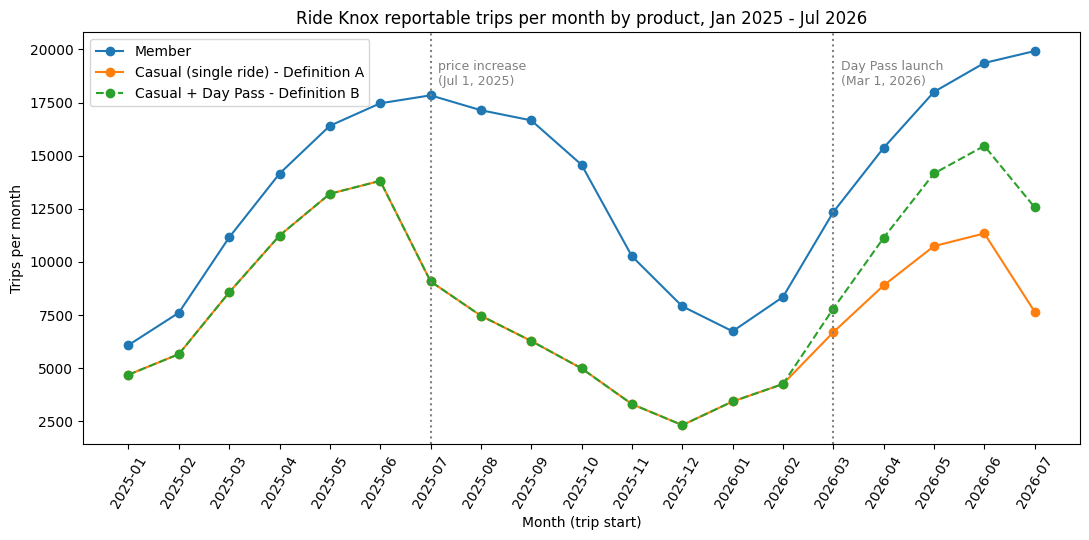

In [ ]:
# D3c: chart 1 - the monthly series that answers the base-effect question
monthly = query(REPORTS["monthly_series"])
wide = monthly.pivot(index="month", columns="rider_type", values="trips").fillna(0)
wide["casual + day_pass"] = wide["casual"] + wide["day_pass"]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(wide.index, wide["member"], marker="o", label="Member")
ax.plot(wide.index, wide["casual"], marker="o", label="Casual (single ride) - Definition A")
ax.plot(wide.index, wide["casual + day_pass"], marker="o", linestyle="--",
        label="Casual + Day Pass - Definition B")
months = list(wide.index)
for when, text in [("2025-07", "price increase\n(Jul 1, 2025)"), ("2026-03", "Day Pass launch\n(Mar 1, 2026)")]:
    ax.axvline(months.index(when), color="gray", linestyle=":")
    ax.text(months.index(when) + 0.15, ax.get_ylim()[1] * 0.88, text, fontsize=9, color="gray")
ax.set_title("Ride Knox reportable trips per month by product, Jan 2025 - Jul 2026")
ax.set_xlabel("Month (trip start)")
ax.set_ylabel("Trips per month")
ax.tick_params(axis="x", rotation=60)
ax.legend()
fig.tight_layout()
fig.savefig("charts/monthly_trips_by_product.png", dpi=150)
plt.show()

**Is a July-only comparison fair? No — it overstates the recovery.**

- The 2025 baseline fell **34.2% from June to July** (casual 13,816 → 9,088).
  In 2026, non-members fell only **18.7%** over the same month (15,461 →
  12,569), and members barely moved in either year (+2.1%, +2.9%). The July
  denominator is unusually small, so *any* July ratio looks better.
- **The month-by-month series shows it.** Definition B goes −26.8% (Jan),
  −24.8%, −8.9% (Mar, Day Pass launches), −0.9%, **+7.2% (May), +11.9% (June)**
  — and then jumps to **+38.3% in July**. That last jump of 26 points arrives in
  the month the *denominator* collapsed, not the month anything changed for
  riders. Definition A climbs steadily, −26.8% → −17.9% (June) → −15.7% (July),
  and never reaches the baseline even against the collapsed month.
- **The honest headline:** against a normal base (June, the last pre-increase
  month), non-members including Day Pass were up **about +12%**; single-ride
  customers alone were down **about 18%**. July's +38.3% is mostly base effect.
  The clean test is August–October 2026 against August–October 2025, when
  both years are on the post-increase prices.

### D4. The capacity verdict: trips per dock, July vs July

**The parameterized report** (`station_pressure` in `reports.sql`) is the one
the team will rerun every month: three `?` placeholders — the date whose dock
counts apply, the first day of the month, the first day of the next month —
and nothing else changes. Below it is called **twice**, for July 2025 and July
2026. The denominator comes from `station_docks` as of each month, so July
2025 divides by **24** docks at S06/S08 and July 2026 by **32**; S25 has no
2025 denominator because it did not exist.

In [ ]:
# D4a: the monthly report, two calls, one query string, only params change
pressure_2025 = query(REPORTS["station_pressure"], params=("2025-07-01", "2025-07-01", "2025-08-01"))
pressure_2026 = query(REPORTS["station_pressure"], params=("2026-07-01", "2026-07-01", "2026-08-01"))
print("July 2026, top 5 by trips per dock:")
print(pressure_2026.head(5).to_string(index=False))

July 2026, top 5 by trips per dock:
station_id             station_name  docks  trips  trips_per_dock
       S01            Market Square     20   2996           149.8
       S02   Gay Street & Union Ave     16   2222           138.9
       S25 Cumberland Ave & 22nd St     16   2171           135.7
       S03              Krutch Park     12   1505           125.4
       S04   Old City - Jackson Ave     16   1948           121.8


In [ ]:
# D4b: July vs July side by side; each year's trips over that year's docks
july = pressure_2025.merge(pressure_2026, on=["station_id", "station_name"], suffixes=("_2025", "_2026"))
for col in ["docks_2025", "trips_2025", "docks_2026", "trips_2026"]:
    july[col] = july[col].astype("Int64")          # whole numbers; <NA> where S25 did not exist yet
july["pressure_change_pct"] = ((july["trips_per_dock_2026"] - july["trips_per_dock_2025"])
                               * 100.0 / july["trips_per_dock_2025"]).round(1)
july["rank_2026"] = july["trips_per_dock_2026"].rank(ascending=False).astype(int)

focus = july.set_index("station_id").loc[FOCUS].reset_index()
print(focus[["station_id", "station_name", "trips_2025", "docks_2025", "trips_per_dock_2025",
             "trips_2026", "docks_2026", "trips_per_dock_2026", "pressure_change_pct",
             "rank_2026"]].to_string(index=False))

# the comparison group: every station whose docks did not change and that existed both years
others = july[~july["station_id"].isin(FOCUS)]
print("\nthe other", len(others), "stations, pooled:",
      format(others["trips_2025"].sum(), ","), "trips /", others["docks_2025"].sum(), "docks =",
      round(others["trips_2025"].sum() / others["docks_2025"].sum(), 1), "per dock (Jul 2025) ->",
      format(others["trips_2026"].sum(), ","), "/", others["docks_2026"].sum(), "=",
      round(others["trips_2026"].sum() / others["docks_2026"].sum(), 1), "per dock (Jul 2026); median station change:",
      others["pressure_change_pct"].median(), "%")

station_id             station_name  trips_2025  docks_2025  trips_per_dock_2025  trips_2026  docks_2026  trips_per_dock_2026  pressure_change_pct  rank_2026
       S06           Hodges Library        2786          24                116.1        2597          32                 81.2                -30.1         12
       S08       Student Union - UT        2579          24                107.5        2460          32                 76.9                -28.5         14
       S25 Cumberland Ave & 22nd St        <NA>        <NA>                  NaN        2171          16                135.7                  NaN          3
       S23  Bearden - Kingston Pike         208          12                 17.3         458          12                 38.2                120.8         23
       S24      Sequoyah Hills Park         216          10                 21.6         272          10                 27.2                 25.9         25

the other 20 stations, pooled: 21,137 trips / 260 d

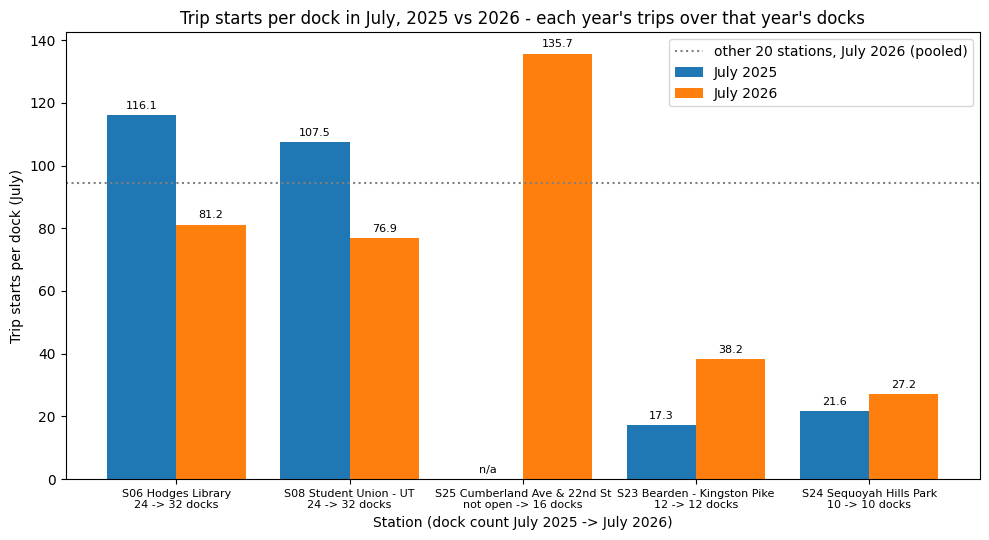

In [ ]:
# D4c: chart 2 - trips per dock at the five stations leadership acted on, July vs July
labels = [sid + " " + name + "\n" + ("not open" if pd.isna(d25) else str(int(d25))) + " -> " + str(int(d26)) + " docks"
          for sid, name, d25, d26 in zip(focus["station_id"], focus["station_name"],
                                         focus["docks_2025"], focus["docks_2026"])]
x = range(len(focus))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar([i - 0.2 for i in x], focus["trips_per_dock_2025"].fillna(0), width=0.4, label="July 2025")
ax.bar([i + 0.2 for i in x], focus["trips_per_dock_2026"], width=0.4, label="July 2026")
for i, v in zip(x, focus["trips_per_dock_2025"]):
    ax.text(i - 0.2, (0 if pd.isna(v) else v) + 2, "n/a" if pd.isna(v) else str(v), ha="center", fontsize=8)
for i, v in zip(x, focus["trips_per_dock_2026"]):
    ax.text(i + 0.2, v + 2, str(v), ha="center", fontsize=8)
ax.axhline(round(others["trips_2026"].sum() / others["docks_2026"].sum(), 1), color="gray", linestyle=":",
           label="other 20 stations, July 2026 (pooled)")
ax.set_xticks(list(x))
ax.set_xticklabels(labels, fontsize=8)
ax.set_title("Trip starts per dock in July, 2025 vs 2026 - each year's trips over that year's docks")
ax.set_ylabel("Trip starts per dock (July)")
ax.set_xlabel("Station (dock count July 2025 -> July 2026)")
ax.legend()
fig.tight_layout()
fig.savefig("charts/july_trips_per_dock_focus_stations.png", dpi=150)
plt.show()

**The capacity verdict: the moves worked.**

- **The campus expansion relieved the two busiest stations.** Hodges Library
  (S06): **2,786 trips ÷ 24 docks = 116.1** per dock in July 2025 → **2,597 ÷ 32
  = 81.2** in July 2026, **−30.1%**. Student Union (S08): **2,579 ÷ 24 = 107.5 →
  2,460 ÷ 32 = 76.9, −28.5%** — while the other 20 stations, whose docks did not
  change, got *busier*: pooled, 21,137 trips ÷ 260 docks = 81.3 → 24,532 ÷ 260 =
  94.4 per dock, **+16.1%** (median station +18.7%, D4b). S06 went from the
  network's busiest tier to 12th of 25, S08 to 14th. Had the
  dock counts been read from "now" (32) for both years, S06's July 2025 figure
  would read 87.1 and the improvement would shrink to −7% — the
  "number moved" trap, avoided.
- **The new station was needed on day one.** Cumberland Ave & 22nd St (S25):
  **2,171 trips ÷ 16 docks = 135.7** per dock — **3rd highest of 25** in its
  fifth month. *(Interpretation: part of the S06/S08 relief is demand moving
  to S25 next door — trips at the S06/S07/S08/S11 campus cluster fell slightly
  while S25 picked up 2,171; that is the network working, not a problem.)*
- **The 2025 rookies split.** Bearden (S23): **208 ÷ 12 = 17.3 → 458 ÷ 12 =
  38.2, +120.8%** — growing fast, keep. Sequoyah Hills (S24): **216 ÷ 10 = 21.6
  → 272 ÷ 10 = 27.2, +25.9%**, in line with the network but still **the
  lowest-pressure station in the system** — the relocation candidate.

Caveats: pressure counts **departures only**
(per my definition in the mopdule project); July 2026 is provisional (late
trips); the 40 quarantined outage trips are not in any station's count.

### D5. The monthly report

Next month, the only edit is the parameters:

```python
query(REPORTS["station_pressure"], params=("2026-08-01", "2026-08-01", "2026-09-01"))
```


---
## Part E — Make it fast, prove it (6 pts)

Two reporting queries, measured **before** any index, then after one index each:

- **Q1 — `station_pressure`**, the monthly report (July 2026 parameters).
- **Q2 — `anniversary_by_product`**, the board's July-vs-July table.

Both filter **only** on a date window of `start_time` and both read
`report_trips`, whose filter needs `end_time`.

In [ ]:
# E1: baselines - plan, time and size with no indexes on trips
Q1, Q1_PARAMS = REPORTS["station_pressure"], ("2026-07-01", "2026-07-01", "2026-08-01")
Q2, Q2_PARAMS = REPORTS["anniversary_by_product"], ()


def plan(sql, params=()):
    """The query plan's lines that touch the trips table."""
    detail = query("EXPLAIN QUERY PLAN " + sql, params=params)["detail"]
    return [line for line in detail if "trips" in line]


results = []
size_before = db_size_mb()
for label, sql, params in [("Q1 station_pressure", Q1, Q1_PARAMS), ("Q2 anniversary_by_product", Q2, Q2_PARAMS)]:
    results.append({"query": label, "stage": "before", "ms": timed(sql, params), "plan": plan(sql, params)})
print("database size before indexes:", size_before, "MB")
pd.DataFrame(results)

database size before indexes: 102.7 MB


,query,stage,ms,plan
0,Q1 station_pressure,before,133.3,[SCAN TABLE trips]
1,Q2 anniversary_by_product,before,197.2,[SCAN TABLE trips]


**Both plans say `SCAN TABLE trips`**: all ~418,000 rows read to count one or
two months.

**Column order, tested.** The slides' rule of thumb is "equality columns first,
range columns last", so the reflex index is `(start_station_id, start_time)`.
Below it is created **inside a transaction that is rolled back** (`BEGIN …
ROLLBACK` undoes a `CREATE INDEX` too), just to read Q1's plan. Q1 has **no**
equality on station (it wants every station), so the planner can only walk the
whole index in station order: `SCAN … USING INDEX`, never a `SEARCH`.

In [ ]:
# E2: the reflex column order
run("BEGIN TRANSACTION")
run_all(INDEXES, ["idx_trips_station_first"])
print("Q1 plan with (start_station_id, start_time):", plan(Q1, Q1_PARAMS),
      "|", timed(Q1, Q1_PARAMS), "ms")
run("ROLLBACK")
print("rolled back - the counter-example index no longer exists")

idx_trips_station_first    rows affected: -


Q1 plan with (start_station_id, start_time): ['SCAN TABLE trips USING INDEX idx_trips_station_first'] | 92.3 ms
rolled back - the counter-example index no longer exists


In [ ]:
# E3: the justified indexes (sql/indexes.sql), one per query, re-measured after each
run_all(INDEXES, ["idx_trips_month_station"])
results.append({"query": "Q1 station_pressure", "stage": "after idx_trips_month_station",
                "ms": timed(Q1, Q1_PARAMS), "plan": plan(Q1, Q1_PARAMS)})
results.append({"query": "Q2 anniversary_by_product", "stage": "after idx_trips_month_station (not its own)",
                "ms": timed(Q2, Q2_PARAMS), "plan": plan(Q2, Q2_PARAMS)})
size_mid = db_size_mb()

run_all(INDEXES, ["idx_trips_month_product"])
results.append({"query": "Q2 anniversary_by_product", "stage": "after idx_trips_month_product",
                "ms": timed(Q2, Q2_PARAMS), "plan": plan(Q2, Q2_PARAMS)})
size_after = db_size_mb()

print("database size:", size_before, "MB ->", size_mid, "MB (+1 index) ->", size_after, "MB (+2 indexes):",
      "+" + str(round((size_after - size_before) * 100 / size_before, 1)) + "%")
pd.set_option("display.max_colwidth", 110)
pd.DataFrame(results)

idx_trips_month_station    rows affected: -


idx_trips_month_product    rows affected: -


database size: 102.7 MB -> 115.5 MB (+1 index) -> 129.6 MB (+2 indexes): +26.2%


,query,stage,ms,plan
0,Q1 station_pressure,before,133.3,[SCAN TABLE trips]
1,Q2 anniversary_by_product,before,197.2,[SCAN TABLE trips]
2,Q1 station_pressure,after idx_trips_month_station,20.3,[SEARCH TABLE trips USING INDEX idx_trips_month_station (start_time>? AND start_time<?)]
3,Q2 anniversary_by_product,after idx_trips_month_station (not its own),98.1,"[SEARCH TABLE trips USING INDEX idx_trips_month_station (start_time>? AND start_time<?), SEARCH TABLE trip..."
4,Q2 anniversary_by_product,after idx_trips_month_product,96.5,"[SEARCH TABLE trips USING INDEX idx_trips_month_product (start_time>? AND start_time<?), SEARCH TABLE trip..."


---
## Part F — The memo (10 pts)

*(The same text is in `memo.md`.)*

**To:** Director of Operations, Ride Knox · **From:** Charles Munga Muiruri · **Date:** August 2026
**Re:** 1 year after the price increase: Did riders come back, and did the stations' capacity shifts work?

**Bottom line** 
- Non-member ridership is back, well above last year, but only if Day Pass customers count as returning riders since single-ride customers alone are still fewer. 
- The campus expansion and the new station both worked.

**Evidence**
- July single-ride trips: (currently at 7,661) down 15.7% from July 2025's (9,088).
- Single-ride plus Day Pass: (now at 12,569) up 38.3% from 2025's (9,088).
- Members: (standing at 19,921) up 11.7% from 17,838 in 2025.
- Hodges Library: 81.2 trips per dock (2,597 trips ÷ 32 docks), down 30.1% from 116.1 (2,786 ÷ 24). Student Union: 76.9 (2,460 ÷ 32), down 28.5% from 107.5 (2,579 ÷ 24).
- The new Cumberland Ave & 22nd St station: 135.7 trips per dock (2,171 ÷ 16), third busiest of 25.

**Interpretation** 
The 38.3% is an overstatement of the recovery. Since July 2025 was the collapsed month, single-ride trips had just fallen 34.2% from June's 13,816. However, if the same is measured in June (2026 vs 2025) instead, the same comparison was +11.9% (15,461 vs 13,816). That's a real but modest return carried by the Day Pass.

**Limitations**
1. This compares periods and it cannot prove the Day Pass caused the change since weather and novelty are uncontrolled.
2. July is only provisional since late trips arrive the following month (August), and 40 July 14 trips lacked start times and are thus held aside.
3. Whether Day Pass riders are "returning" riders is a definition rather than a measurement.

**Recommendation** 
- Keep the Day Pass, and judge it on August–October 2026 against August–October 2025, when both years carry the new prices.
- Ask the app vendor to fix the outage records. 
- Every figure now comes from one shared, checked record of every trip the vendor sends, where each delivered row is either counted or set    aside with a written reason.

---
## Reflection + AI disclosure (3 pts)

**Reflection — which single schema decision would be most expensive to change six
months from now, and what did I do to reduce the chance I'll have to?**

Trusting the vendor's `trip_id` as the identity of a trip: If the vendor
ever reuses or renumbers IDs, every monthly load would silently skip real trips
or double-count re-sent ones, and changing the identity would mean rebuilding
`trips` and re-deriving every report. To lower that risk I (1) check the ID's
shape with a `CHECK`, (2) quarantine any `trip_id` that arrives twice with
different content instead of letting the primary key pick a winner, (3) verify,
in the July inspection, that re-sent IDs are identical to what we hold, and
(4) keep every raw row in the `intake` ledger with its file and row number, so the
database can always be rebuilt from the deliveries under a different rule.

**AI disclosure.**

I used a two generative AI tools in this assignment (Claude CLI AND THE Copilot in VSCode).
Key use-cases include drafting primary versions of the SQL files, checking the notebook's code 
when an error occured and simplifying SQL funstions with common table expressions (CTE).
I reviewed, ran and verified every statement, and the design decisions and conclusions are my own.

In [ ]:
# Close the connection: the database file on disk is the build product
con.close()
print("closed |", DB, "on disk:", round(os.path.getsize(DB) / 1_048_576, 1), "MB")

closed | ride_knox_v2.db on disk: 129.6 MB
